<h1><center> Polynomial Regression

In [54]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns



In [55]:
# Données initiales
x = np.arange(0, 30)
y = [3, 4, 5, 7, 10, 8, 9, 10, 10, 23, 27, 44, 50, 63, 67, 60, 62, 70, 75, 88, 81, 87, 95, 100, 108, 135, 151, 160, 169, 179]

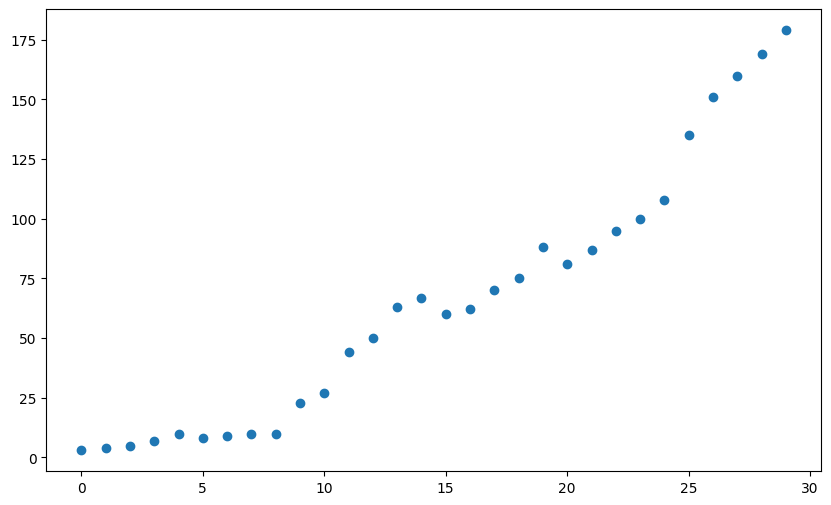

In [56]:
plt.figure(figsize= (10, 6))
plt.scatter(x,y)
plt.show()

In [57]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree= 2, include_bias= False)

In [58]:
poly_features = poly.fit_transform(x.reshape(-1, 1))
poly_features

array([[  0.,   0.],
       [  1.,   1.],
       [  2.,   4.],
       [  3.,   9.],
       [  4.,  16.],
       [  5.,  25.],
       [  6.,  36.],
       [  7.,  49.],
       [  8.,  64.],
       [  9.,  81.],
       [ 10., 100.],
       [ 11., 121.],
       [ 12., 144.],
       [ 13., 169.],
       [ 14., 196.],
       [ 15., 225.],
       [ 16., 256.],
       [ 17., 289.],
       [ 18., 324.],
       [ 19., 361.],
       [ 20., 400.],
       [ 21., 441.],
       [ 22., 484.],
       [ 23., 529.],
       [ 24., 576.],
       [ 25., 625.],
       [ 26., 676.],
       [ 27., 729.],
       [ 28., 784.],
       [ 29., 841.]])

In [59]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()

In [60]:
model.fit(poly_features, y)

LinearRegression()

In [61]:
y_predict = model.predict(poly_features)

In [62]:
model.coef_

array([1.17020102, 0.16361433])

In [63]:
model.intercept_

1.708064516129042

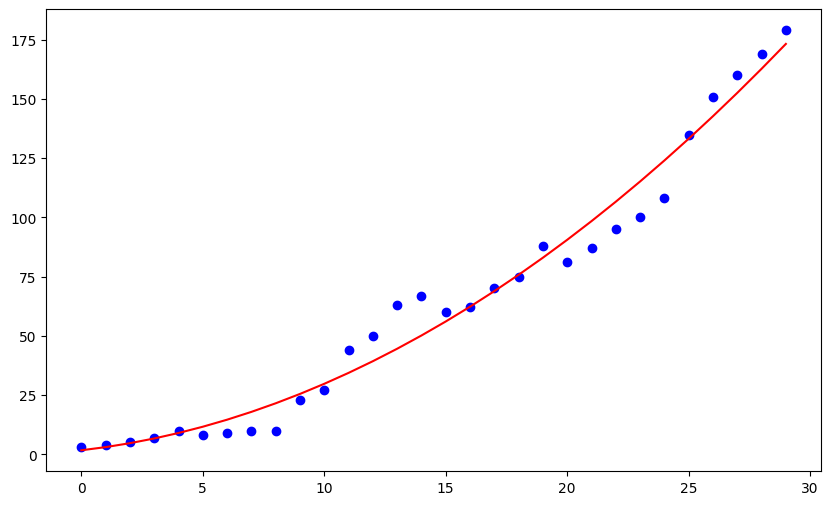

In [64]:
plt.figure(figsize=(10,6))
plt.scatter(x, y, color= 'blue', label= 'Data')
plt.plot(x, y_predict, color= 'red', label= 'fonction polynomiale')
plt.show()

<h2> Polynomial Regression model with multiple features

In [72]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

In [80]:
# création des données
np.random.seed(1)

x_1 = np.absolute(np.random.randn(100, 1) * 10) # (100, 1) 100lignes et 1 colonne distribution normale

x_2 = np.absolute(np.random.randn(100, 1) * 30)


y = 2*x_1**2 + 3*x_1 + 2 + np.random.randn(100, 1)*20

- Génère 100 valeurs aléatoires selon une loi normale centrée réduite (certaines négatives) multiplié par 10 (ou 30 pour x2).

- Prend leur valeur absolue pour obtenir uniquement des valeurs positives.

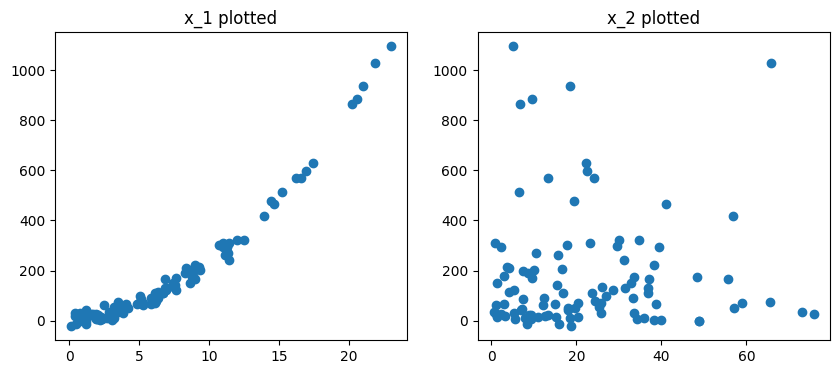

In [82]:
fix, axes = plt.subplots(nrows=1, ncols= 2, figsize=(10, 4))
axes[0].scatter(x_1, y)
axes[1].scatter(x_2, y)

axes[0].set_title("x_1 plotted")
axes[1].set_title("x_2 plotted")

plt.show()

In [83]:
df = pd.DataFrame({"x_1":x_1.reshape(100,), "x_2":x_2.reshape(100,), "y":y.reshape(100,)}, index=range(0,100))
df

,x_1,x_2,y
0,16.243454,13.413857,570.412369
1,6.117564,36.735231,111.681987
2,5.281718,12.104749,62.392124
3,10.729686,17.807356,303.538953
4,8.654076,32.847355,151.109269
...,...,...,...
95,0.773401,48.823150,-0.430738
96,3.438537,18.069578,44.308720
97,0.435969,12.608466,19.383456
98,6.200008,24.328550,78.371729


In [84]:
from sklearn.model_selection import train_test_split
X, y = df[["x_1", "x_2"]], df[["y"]]


poly = PolynomialFeatures(degree=2, include_bias= False)
poly_features = poly.fit_transform(X)


X_train, X_test, y_train, y_test = train_test_split(poly_features, y, test_size= 0.3, random_state= 42)

In [85]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [86]:
y_pred = model.predict(X_test)

In [88]:
from sklearn.metrics import mean_squared_error

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(rmse)

20.937707839078683


In [89]:
model.coef_

array([[ 3.61945509, -1.0859955 ,  1.89905813,  0.0207338 ,  0.01300394]])

In [90]:
model.intercept_

array([14.12343604])